<a href="https://colab.research.google.com/github/idanm-commiting/Sanitation-Project/blob/main/Copy_of_Copy_of_Juan's_Work2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

base_url = "https://raw.githubusercontent.com/idanm-commiting/Sanitation-Project/main/"
frames = []

for part in ["1", "2a", "2b", "3"]:
    filename = f"Food_Inspections_part_{part}.zip"
    frame = pd.read_csv(base_url + filename, compression="zip", low_memory=False)
    frames.append(frame)

DataFrame12 = pd.concat(frames, ignore_index=True)

DataFrame12 = DataFrame12.rename(columns={"Address": "Street Address",
    "Zip": "ZIP Code"})

DataFrame12["Record Date"] = pd.to_datetime(
    DataFrame12["Inspection Date"], errors="coerce", format="mixed")

DataFrame12["Facility Type"] = (
    DataFrame12["Facility Type"]
    .fillna("Blank")
    .str.strip()
    .replace("", "Blank"))

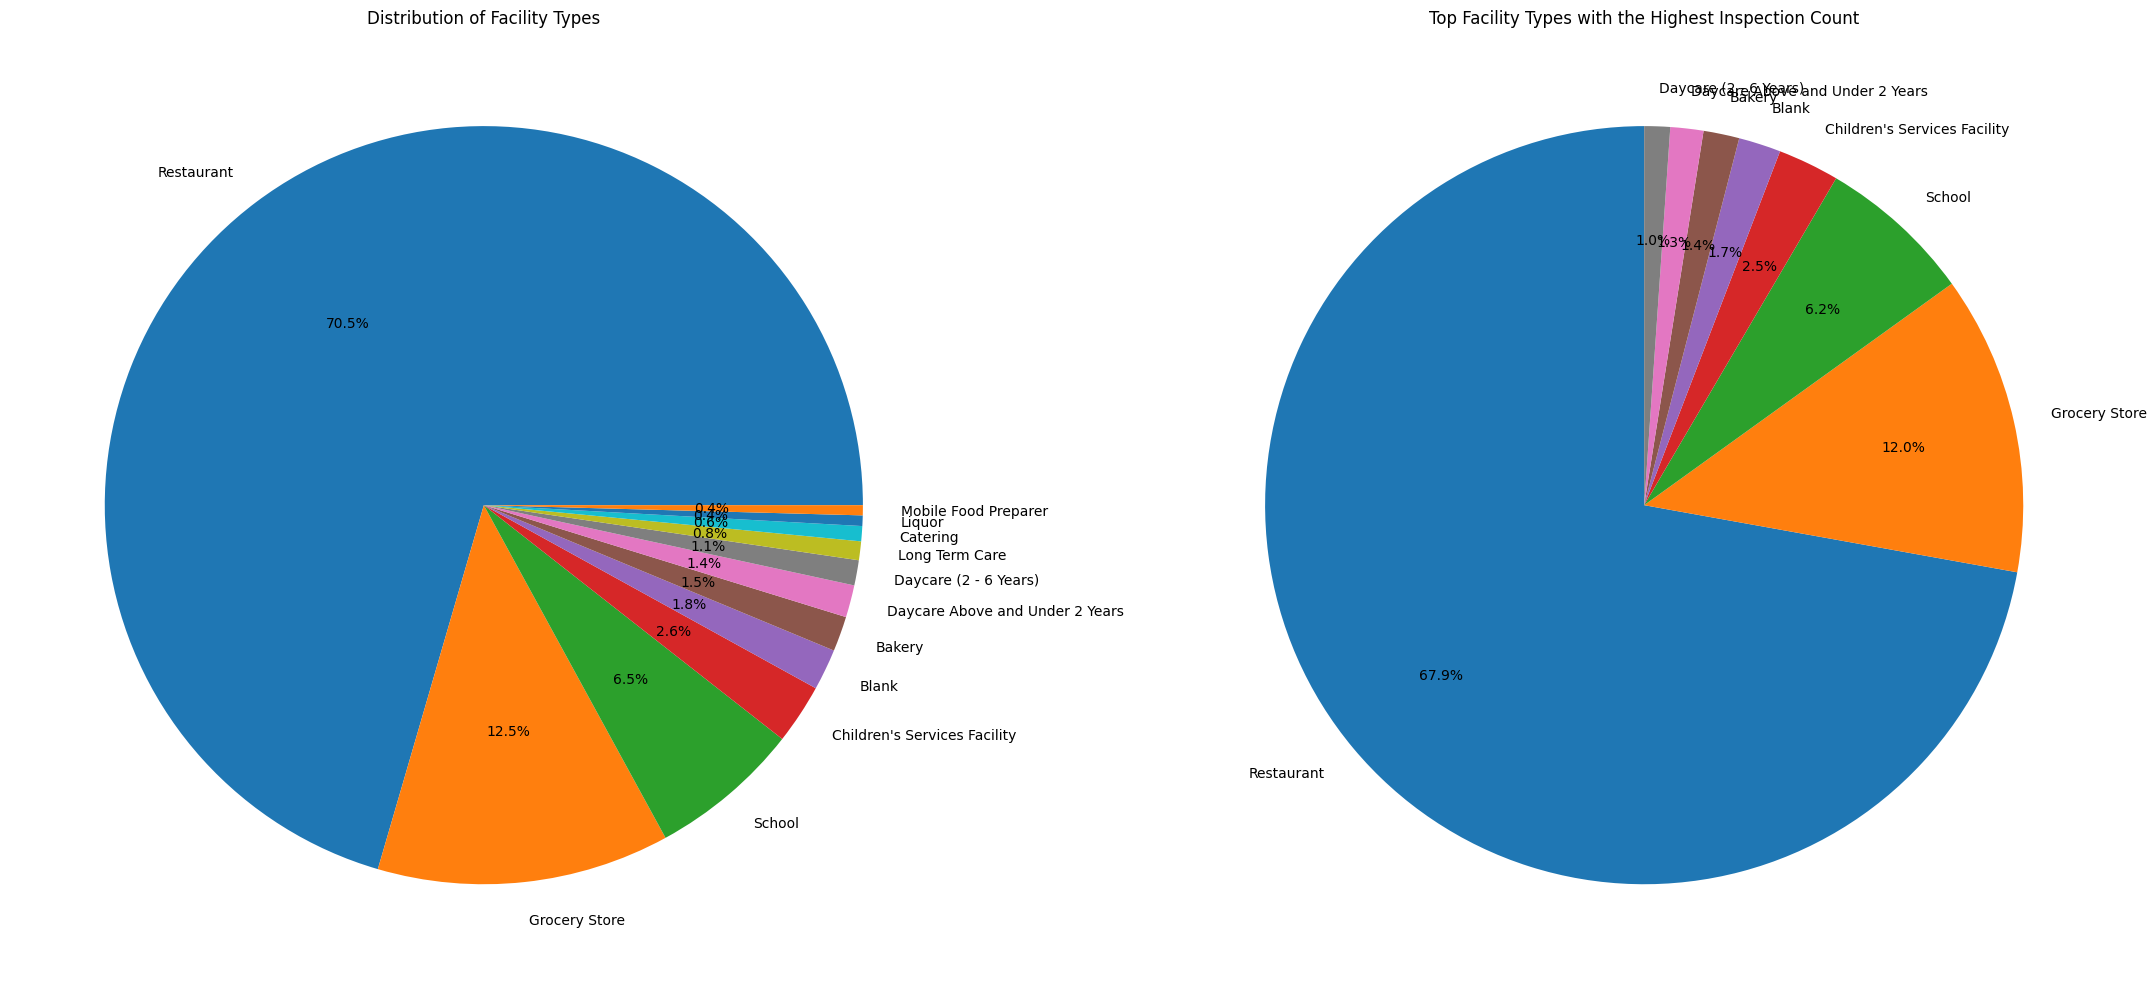

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(22, 10))

# First chart
facility_counts = DataFrame12["Facility Type"].value_counts()
facility_counts = facility_counts.loc[facility_counts >= 1000]

axes[0].pie(facility_counts, labels=facility_counts.index, autopct="%1.1f%%")
axes[0].set_title("Distribution of Facility Types")

# Second chart: percentages inside the pie
counts = (DataFrame12["Facility Type"].fillna("Blank")
          .str.strip().replace("", "Blank").value_counts())

top8 = counts.head(8)

axes[1].pie(top8,labels=top8.index,autopct=lambda pct: f"{pct * top8.sum() / counts.sum():.1f}%",pctdistance=0.7,startangle=90)
axes[1].set_title(
    "Top Facility Types with the Highest Inspection Count")

plt.tight_layout()
plt.show()

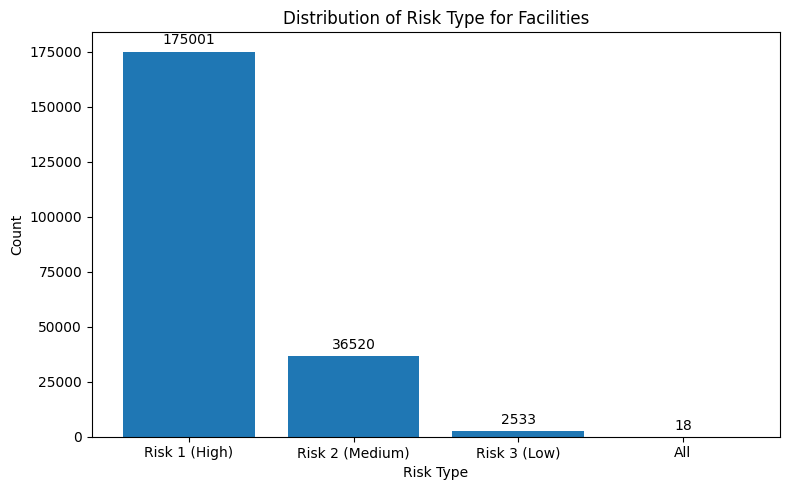

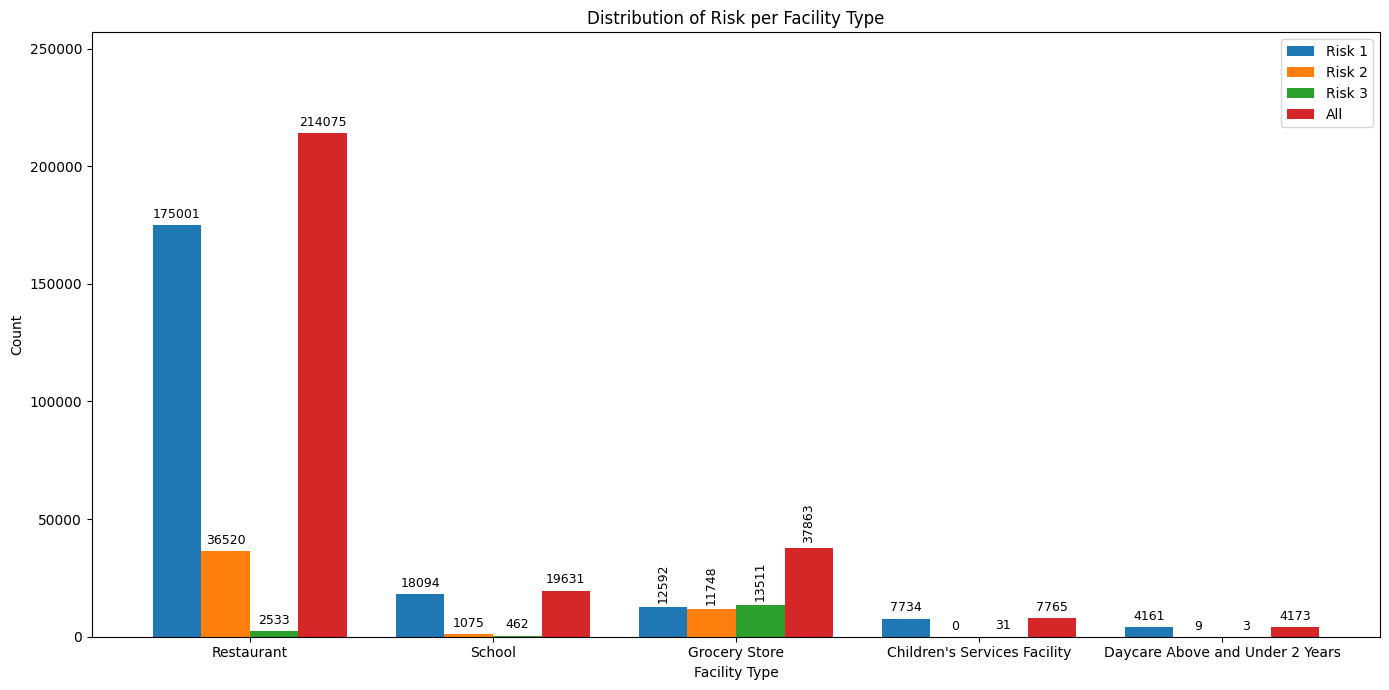

In [7]:
restaurants = DataFrame12.loc[
    DataFrame12["Facility Type"].str.lower() == "restaurant"]
risk_counts = restaurants["Risk"].value_counts()
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(risk_counts.index, risk_counts.values)
ax.set(title="Distribution of Risk Type for Facilities",xlabel="Risk Type",ylabel="Count")
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


counts = pd.crosstab(facilities, risks).reindex(columns=["1", "2", "3"], fill_value=0)
counts.columns = ["Risk 1", "Risk 2", "Risk 3"]
counts["All"] = facilities.value_counts()
top5 = counts.nlargest(5, "Risk 1")
ax = top5.plot.bar(figsize=(14, 7), rot=0, width=0.8,title="Distribution of Risk per Facility Type",
    xlabel="Facility Type", ylabel="Count")
for bars in ax.containers:
    labels = ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
    for label, facility in zip(labels, top5.index):
        if facility.lower() == "grocery store":
            label.set_rotation(90)

ax.margins(y=0.2)
plt.tight_layout()
plt.show()

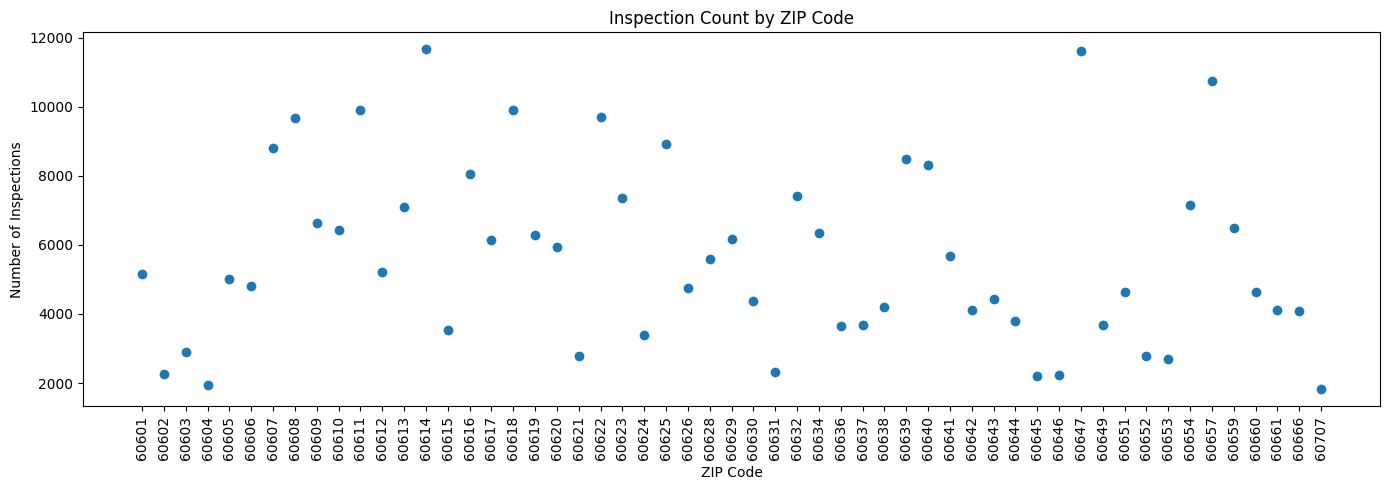

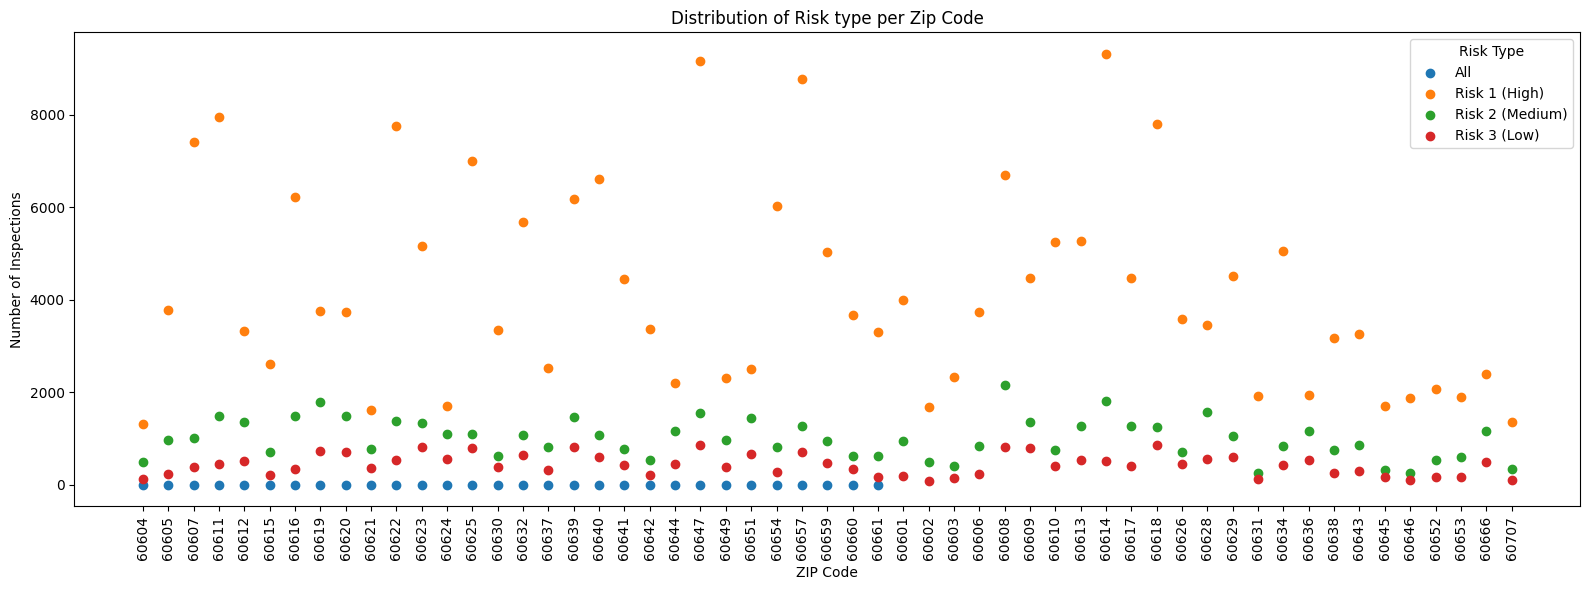

In [11]:
zip_codes = DataFrame12["ZIP Code"].dropna().astype(str)
zip_codes = zip_codes.str.replace(r"\.0$", "", regex=True)

zip_counts = zip_codes.value_counts().sort_index()
zip_counts = zip_counts.loc[zip_counts >= 1500]

plt.figure(figsize=(14, 5))
plt.scatter(zip_counts.index, zip_counts.values)
plt.title("Inspection Count by ZIP Code")
plt.xlabel("ZIP Code")
plt.ylabel("Number of Inspections")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


data = DataFrame12.rename(columns={"ZIP Code": "Zip"}).copy()
data["Zip"] = data["Zip"].astype("string").str.replace(r"\.0$", "", regex=True)

zip_counts = data["Zip"].value_counts()
selected = data.loc[data["Zip"].isin(zip_counts[zip_counts > 1500].index)]
counts = selected.groupby(["Zip", "Risk"]).size().reset_index(name="Count")

plt.figure(figsize=(16, 6))
for risk, group in counts.groupby("Risk"):plt.scatter(group["Zip"], group["Count"], label=risk)
plt.title("Distribution of Risk type per Zip Code")
plt.xlabel("ZIP Code")
plt.ylabel("Number of Inspections")
plt.xticks(rotation=90)
plt.legend(title="Risk Type")
plt.tight_layout()
plt.show()

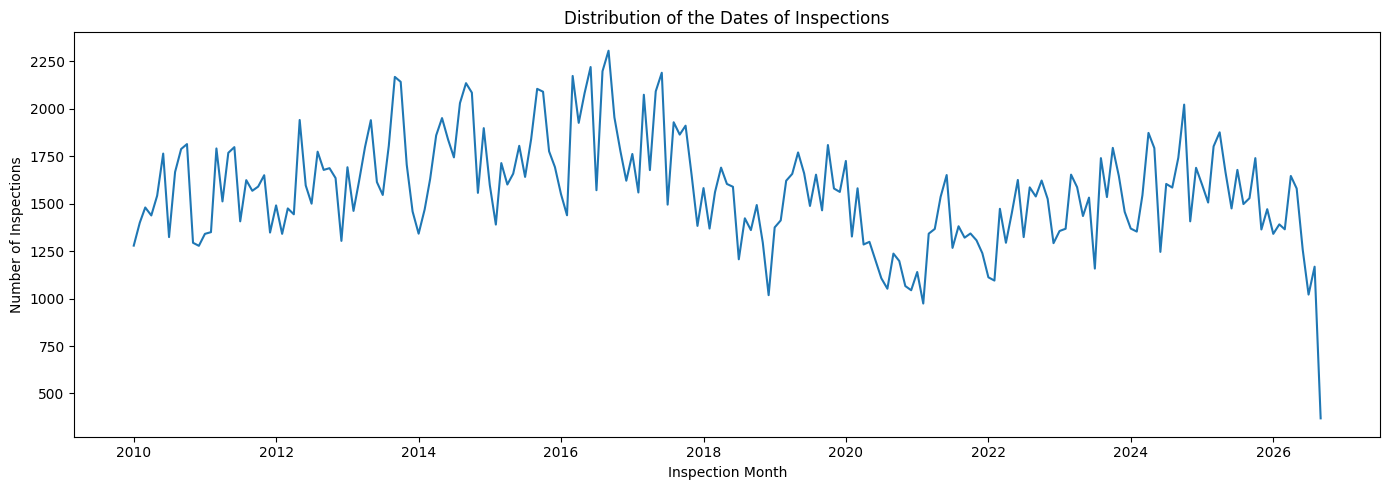

In [ ]:
dated_inspections = DataFrame12.dropna(subset=["Record Date"]).copy()
dated_inspections["Month"] = dated_inspections["Record Date"].dt.to_period("M")

monthly_counts = dated_inspections.groupby("Month").size()
monthly_counts.index = monthly_counts.index.to_timestamp()

plt.figure(figsize=(14, 5))
plt.plot(monthly_counts.index, monthly_counts.values)
plt.title("Distribution of the Dates of Inspections")
plt.xlabel("Inspection Month")
plt.ylabel("Number of Inspections")
plt.tight_layout()
plt.show()

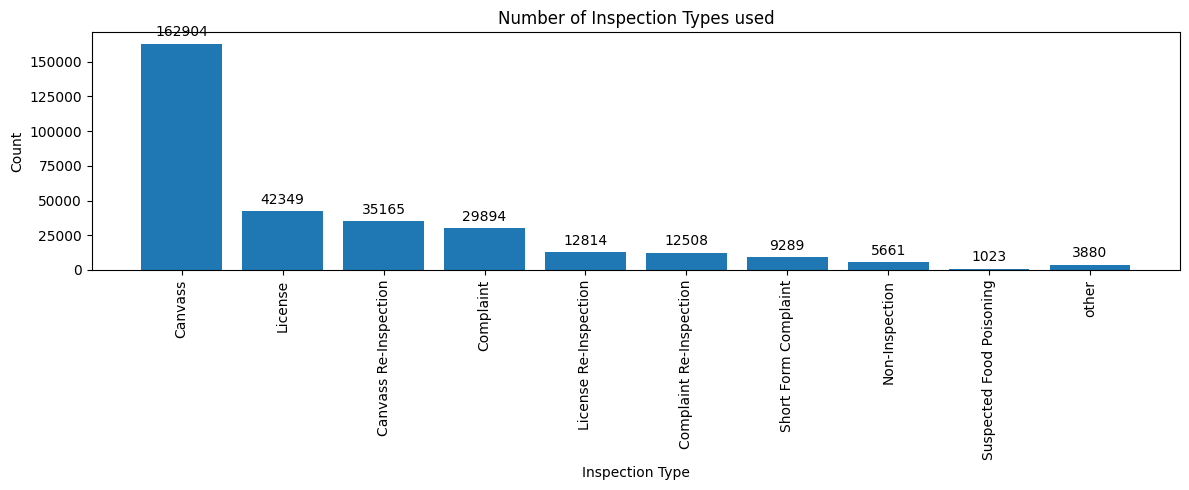

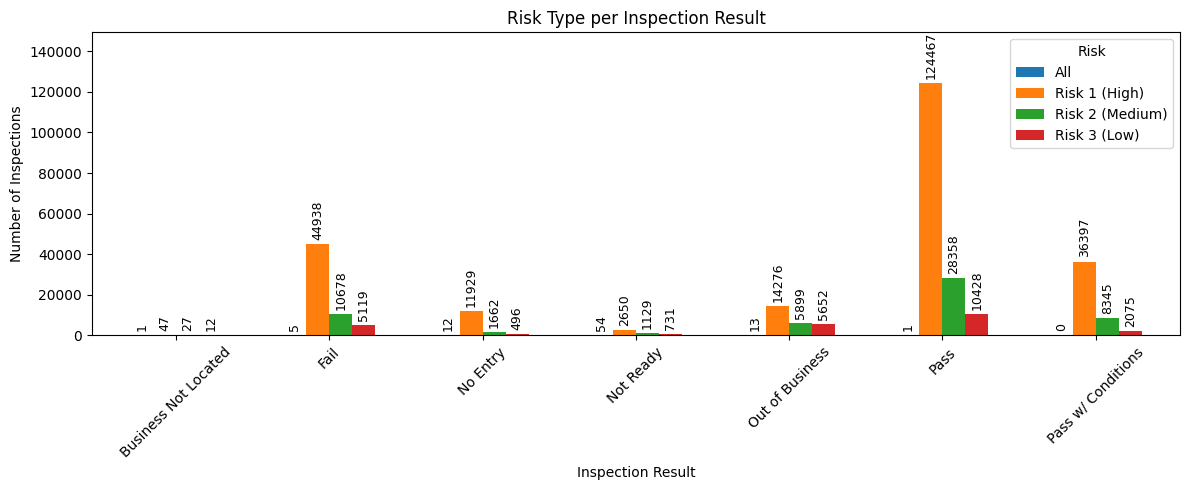

In [14]:
inspection_counts = DataFrame12["Inspection Type"].value_counts()
shown = inspection_counts.loc[inspection_counts >= 1000].copy()
shown.loc["other"] = inspection_counts.loc[inspection_counts < 1000].sum()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(shown.index, shown.values)
ax.set(title="Number of Inspection Types used",xlabel="Inspection Type",ylabel="Count")
ax.bar_label(bars, padding=3)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

counts = pd.crosstab(DataFrame12["Results"], DataFrame12["Risk"])
ax = counts.plot.bar(
    figsize=(12, 5), width=0.6, rot=45,
    title="Risk Type per Inspection Result",
    xlabel="Inspection Result", ylabel="Number of Inspections")
for bars in ax.containers:ax.bar_label(bars, fmt="%.0f", padding=3, rotation=90, fontsize=9)
ax.margins(y=0.2)
plt.tight_layout()
plt.show()

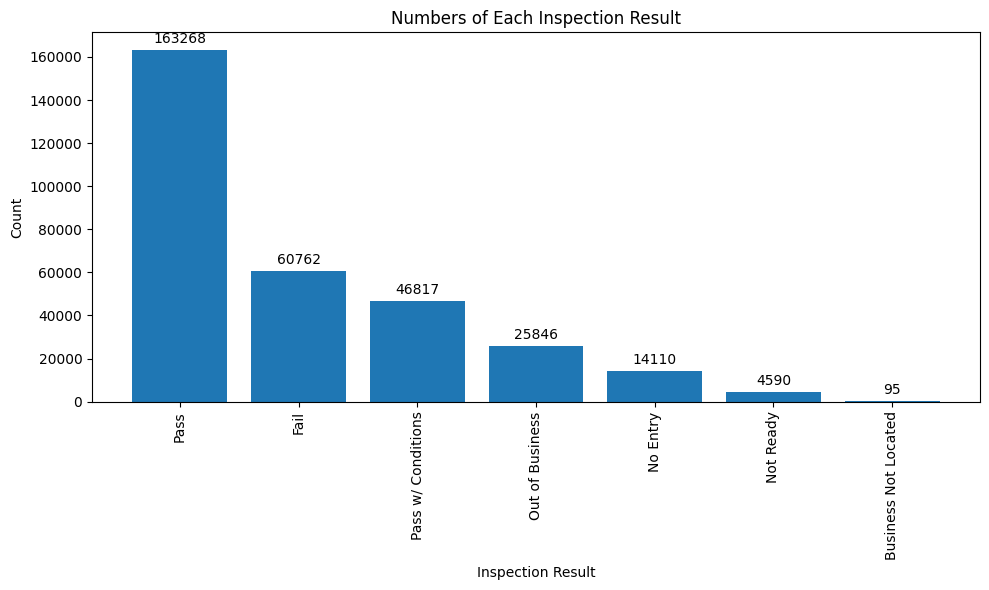

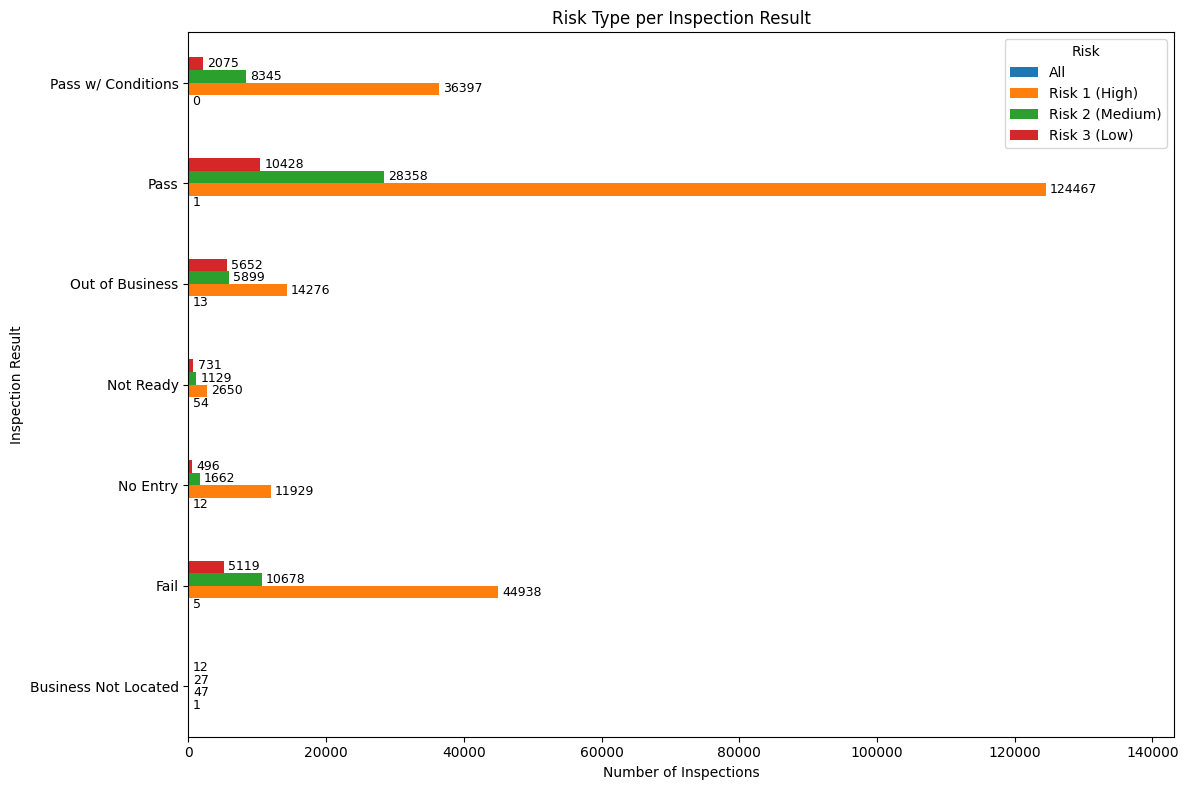

In [16]:
result_counts = DataFrame12["Results"].fillna("Blank").value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(result_counts.index, result_counts.values)
ax.set(title="Numbers of Each Inspection Result",xlabel="Inspection Result",
    ylabel="Count")
ax.bar_label(bars, padding=3)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

counts = pd.crosstab(DataFrame12["Results"], DataFrame12["Risk"])
ax = counts.plot.barh(figsize=(12, 8),title="Risk Type per Inspection Result",
    xlabel="Number of Inspections", ylabel="Inspection Result")
for bars in ax.containers:ax.bar_label(bars, fmt="%.0f", padding=3, fontsize=9)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

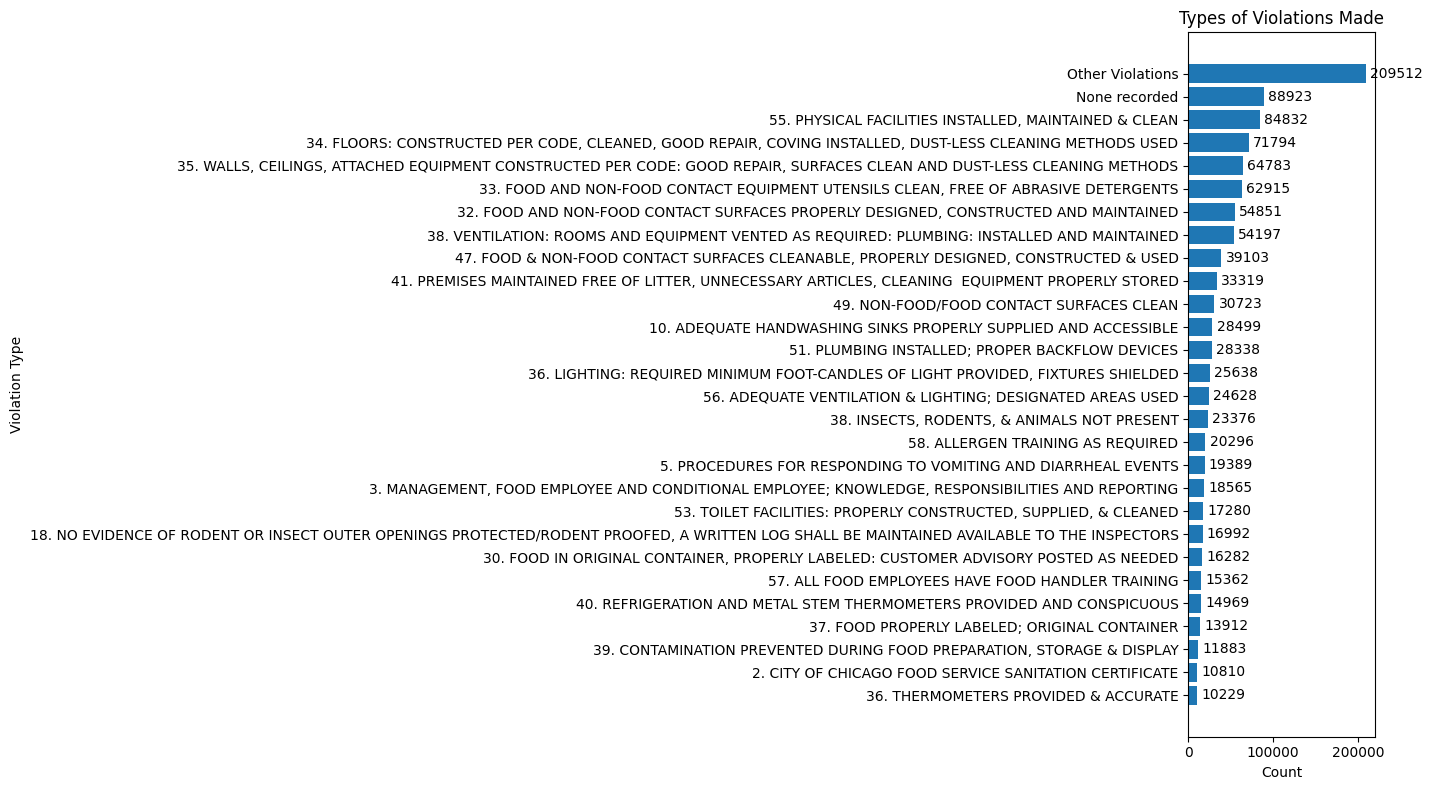

In [ ]:
violations = DataFrame12["Violations"].fillna("None recorded")
violations = violations.str.strip().replace("", "None recorded")
violations = violations.str.split("|", regex=False).explode()
violations = violations.str.split(" - Comments:", n=1).str[0].str.strip()

violation_counts = violations.value_counts()
small = (violation_counts < 10000) & (violation_counts.index != "None recorded")

shown = violation_counts.loc[~small].copy()
shown.loc["Other Violations"] = violation_counts.loc[small].sum()
shown = shown.sort_values()

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(shown.index, shown.values)
ax.set(
    title="Types of Violations Made",
    xlabel="Count",
    ylabel="Violation Type"
)
ax.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()

In [ ]:
DataFrame12.dtypes

,0
Inspection ID,int64
DBA Name,object
AKA Name,object
License #,float64
Facility Type,object
Risk,object
Address,object
City,object
State,object
Zip,float64


In [ ]:
import pandas as pd

facility = pd.read_csv("/content/summary.csv", header=1, usecols=[2, 3])
display(facility)

FileNotFoundError: [Errno 2] No such file or directory: '/content/summary.csv'

In [ ]:
!find /content -name "summary.csv"

/content/summary.csv
